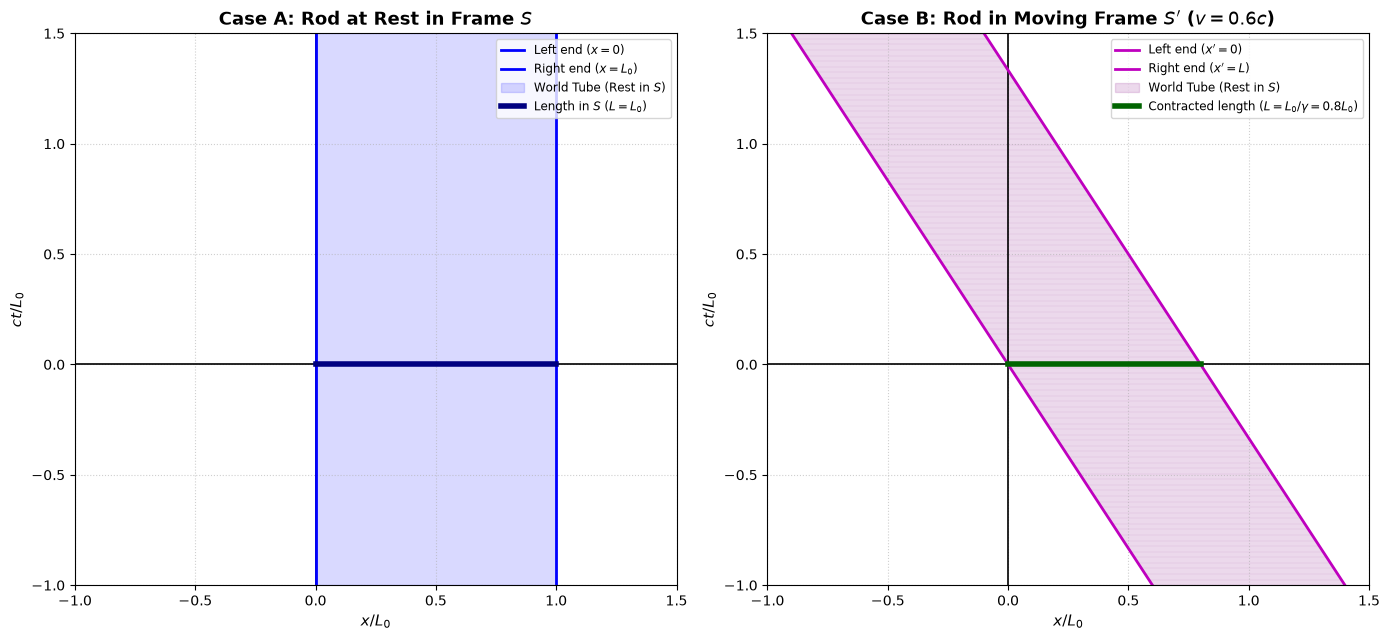

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Set up side-by-side figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5))

beta = -0.6
gamma = 1 / np.sqrt(1 - beta**2) # gamma = 1.25

# --- Case 1: Rod at Rest in Frame S ---
# Axes boundaries
x_min, x_max = -1.0, 1.5
ct_min, ct_max = -1.0, 1.5

# Frame S axes
ax1.axhline(0, color='black', linewidth=1.2)
ax1.axvline(0, color='black', linewidth=1.2)

# World tube for rod at rest in S
ct_vals = np.linspace(ct_min, ct_max, 200)
ax1.plot([0, 0], [ct_min, ct_max], 'b-', linewidth=2, label='Left end ($x=0$)')
ax1.plot([1, 1], [ct_min, ct_max], 'b-', linewidth=2, label='Right end ($x=L_0$)')
ax1.fill_betweenx(ct_vals, 0, 1, color='blue', alpha=0.15, label='World Tube (Rest in $S$)')


# Simultaneous slices
# Slice at ct = 0 (in S)
ax1.plot([0, 1], [0, 0], color='navy', linewidth=4, label='Length in $S$ ($L = L_0$)')


ax1.set_xlim(x_min, x_max)
ax1.set_ylim(ct_min, ct_max)
ax1.set_xlabel('$x / L_0$', fontsize=11)
ax1.set_ylabel('$ct / L_0$', fontsize=11)
ax1.set_title('Case A: Rod at Rest in Frame $S$', fontsize=13, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', fontsize=8.5)


# --- Case 2: Rod in Frame S' (Moving at v = 0.6c relative to S) ---
# Frame S axes
ax2.axhline(0, color='black', linewidth=1.2)
ax2.axvline(0, color='black', linewidth=1.2)



# Worldlines of ends of rod moving with v = 0.6c (at rest in S')
# Left end: x' = 0 => x = beta * ct
# Right end: x' = L0 => x - beta*ct = L0/gamma = 0.8 L0 => x = beta*ct + L0/gamma
# Wait! Lorentz transformation: x' = gamma (x - beta ct)
# So x' = 0 => x = beta ct
# x' = L0 => x = beta ct + L0 / gamma
width_in_S = 1.0 / gamma # 0.8 L0

x_left = beta * ct_vals
x_right = beta * ct_vals + width_in_S

ax2.plot(x_left, ct_vals, 'm-', linewidth=2, label="Left end ($x'=0$)")
ax2.plot(x_right, ct_vals, 'm-', linewidth=2, label="Right end ($x'=L$)")

# Fill world tube
for ct in np.linspace(ct_min, ct_max, 100):
    ax2.plot([beta*ct, beta*ct + width_in_S], [ct, ct], color='purple', alpha=0.03)

# Fill between worldlines
ax2.fill_betweenx(ct_vals, x_left, x_right, color='purple', alpha=0.15, label="World Tube (Rest in $S$)")

# Measured length in frame S (simultaneous at ct = 0)
ax2.plot([0, width_in_S], [0, 0], color='darkgreen', linewidth=4, label=r'Contracted length ($L = L_0/\gamma = 0.8 L_0$)')



ax2.set_xlim(x_min, x_max)
ax2.set_ylim(ct_min, ct_max)
ax2.set_xlabel('$x / L_0$', fontsize=11)
ax2.set_ylabel('$ct / L_0$', fontsize=11)
ax2.set_title("Case B: Rod in Moving Frame $S'$ ($v = 0.6c$)", fontsize=13, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.savefig('spacetime_diagram_comparison.png', dpi=300)
plt.show()